<a href="https://colab.research.google.com/github/asyatahir/Reducing-Food-Waste-and-Optimizing-Food-Donation/blob/main/datasc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. LIBRARIES IMPORTED




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error



2.DATA LOADED

In [ ]:
restaurant_df = pd.read_csv('food_wastage_data.csv')
donation_df = pd.read_csv('Donations.csv')


3. DATA VIEW (RESTAURANT)

In [ ]:
restaurant_df.head()

,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


In [ ]:
restaurant_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1782 entries, 0 to 1781
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Type of Food           1782 non-null   object
 1   Number of Guests       1782 non-null   int64 
 2   Event Type             1782 non-null   object
 3   Quantity of Food       1782 non-null   int64 
 4   Storage Conditions     1782 non-null   object
 5   Purchase History       1782 non-null   object
 6   Seasonality            1782 non-null   object
 7   Preparation Method     1782 non-null   object
 8   Geographical Location  1782 non-null   object
 9   Pricing                1782 non-null   object
 10  Wastage Food Amount    1782 non-null   int64 
dtypes: int64(3), object(8)
memory usage: 153.3+ KB


3. DATA VIEW (DONATION)

In [ ]:
donation_df.head()

,Item No.,Description,Storage Type,Donor,Posting Date,FBC Product Type Code,Quantity,Unit of Measure,Ext. Gross Weight
0,BF1182,HOME 360 BABY PEDIALYTE,DRY,Food Lion Distribution Center,9/13/18,BEVERAGES,34,CS,510
1,BF1307,PLUM ORGANICS MANGO CARROT & COCONUT CRE,DRY,Food Lion Distribution Center,1/24/19,BABY FOOD,73,CS,73
2,BF1307,PLUM ORGANICS MANGO CARROT & COCONUT CRE,DRY,Food Lion Distribution Center,2/19/19,BABY FOOD,242,CS,242
3,BF1307,PLUM ORGANICS MANGO CARROT & COCONUT CRE,DRY,Food Lion Distribution Center,3/4/2019,BABY FOOD,76,CS,76
4,BF1366,ALWAYS MY BABY MILK-BASED FORMULA W/IRON,DRY,Food Lion Distribution Center,2/19/19,BABY FOOD,44,CS,484


In [ ]:
donation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95480 entries, 0 to 95479
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Item No.               95480 non-null  object
 1   Description            95480 non-null  object
 2   Storage Type           95479 non-null  object
 3   Donor                  95479 non-null  object
 4   Posting Date           95479 non-null  object
 5   FBC Product Type Code  95479 non-null  object
 6   Quantity               95479 non-null  object
 7   Unit of Measure        95478 non-null  object
 8   Ext. Gross Weight      95479 non-null  object
dtypes: object(9)
memory usage: 6.6+ MB


4. CHECK MISSING VALUE

In [ ]:
restaurant_df.isnull().sum()

,0
Type of Food,0
Number of Guests,0
Event Type,0
Quantity of Food,0
Storage Conditions,0
Purchase History,0
Seasonality,0
Preparation Method,0
Geographical Location,0
Pricing,0


In [ ]:
donation_df.isnull().sum()

,0
Item No.,0
Description,0
Storage Type,1
Donor,1
Posting Date,1
FBC Product Type Code,1
Quantity,1
Unit of Measure,2
Ext. Gross Weight,1


5.REMOVE MISSING VALUE

In [ ]:
restaurant_df.dropna(inplace=True)
donation_df.dropna(inplace=True)

6.REMOVE DUPLICATE MISING VALUE

In [ ]:
restaurant_df.drop_duplicates(inplace=True)
donation_df.drop_duplicates(inplace=True)


7. CREATE DATE COLUMN (ARIMA NEED A TIME SERIES DATA)

In [ ]:
restaurant_df['Date'] = pd.date_range(
    end='2026-06-09',
    periods=len(restaurant_df),
    freq='D'
)

In [ ]:
restaurant_df.head()

,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount,Date
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25,2022-01-04
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40,2022-01-05
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27,2022-01-06
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32,2022-01-07
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25,2022-01-08


8. EDA : FOOD WASTAGE TREND ##





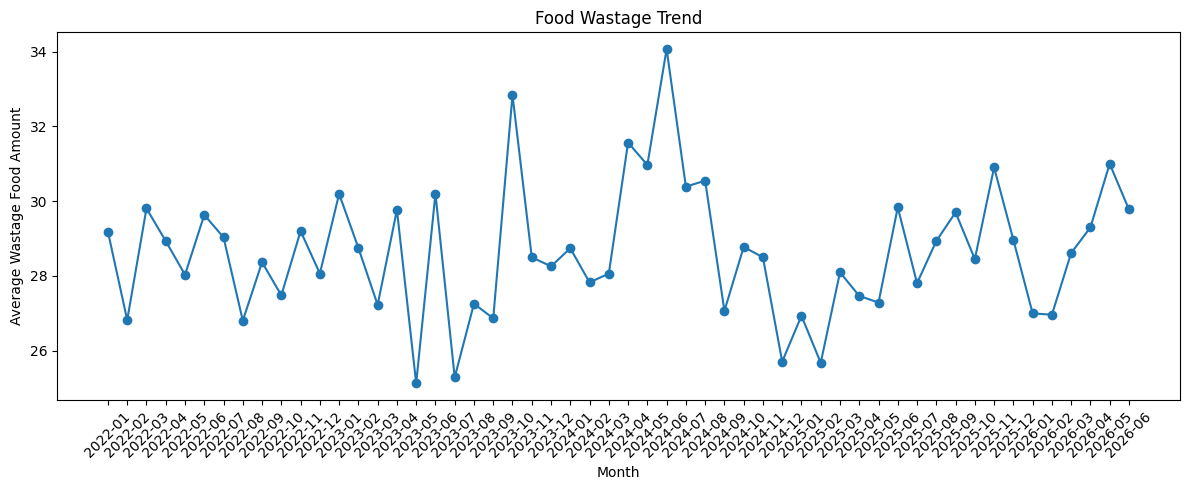

In [ ]:
monthly_trend = restaurant_df.groupby(
    restaurant_df['Date'].dt.to_period('M')
)['Wastage Food Amount'].mean()

monthly_trend.index = monthly_trend.index.astype(str)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_trend,
    marker='o'
)

plt.title('Food Wastage Trend')

plt.xlabel('Month')

plt.ylabel('Average Wastage Food Amount')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

8. EDA: MOST WASTED FOOD TYPE

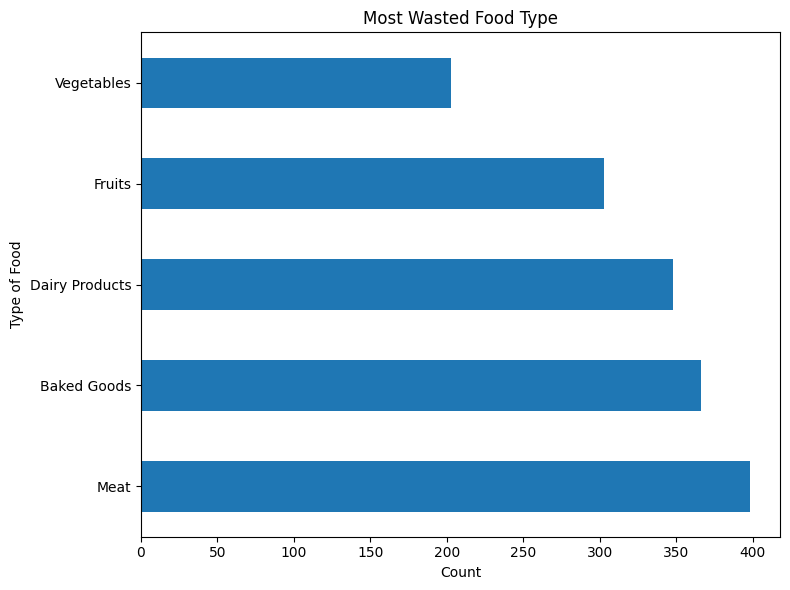

In [ ]:
food_counts = restaurant_df[
    'Type of Food'
].value_counts()

plt.figure(figsize=(8,6))

food_counts.plot(kind='barh')

plt.title('Most Wasted Food Type')

plt.xlabel('Count')

plt.ylabel('Type of Food')

plt.tight_layout()

plt.show()

8.EDA: WASTAGE BY EVENT TYPE

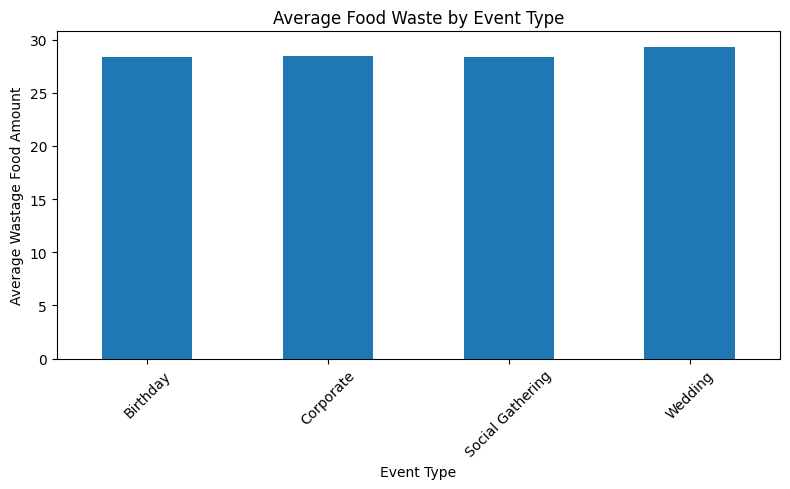

In [ ]:
event_avg = restaurant_df.groupby(
    'Event Type'
)['Wastage Food Amount'].mean()

plt.figure(figsize=(8,5))

event_avg.plot(
    kind='bar'
)

plt.title('Average Food Waste by Event Type')

plt.xlabel('Event Type')

plt.ylabel('Average Wastage Food Amount')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

8.EDA: WASTE BY STORAGE CONDITION

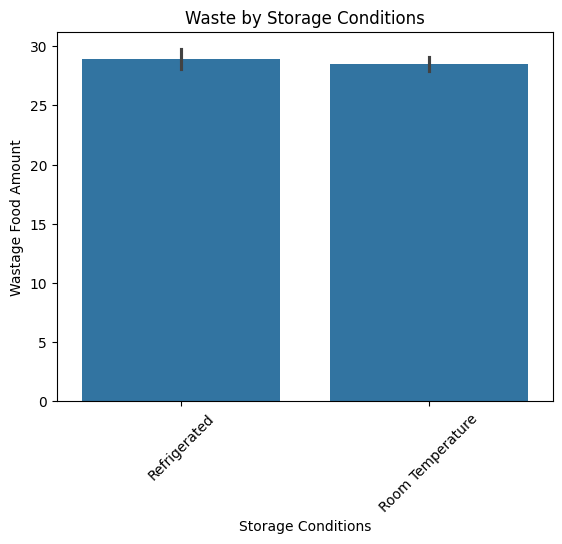

In [ ]:
sns.barplot(
    x='Storage Conditions',
    y='Wastage Food Amount',
    data=restaurant_df
)

plt.xticks(rotation=45)

plt.title('Waste by Storage Conditions')

plt.show()

Correlation Heatmap

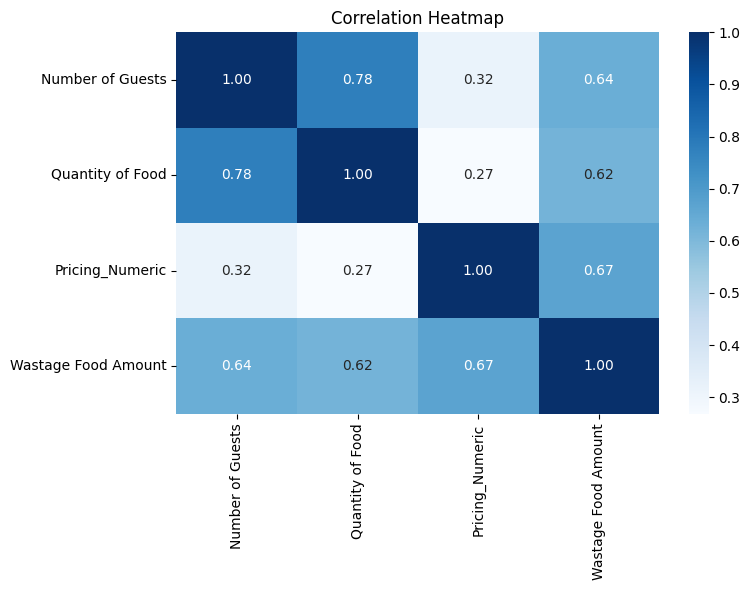

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation Heatmap

# Map 'Pricing' column to numerical values
pricing_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
restaurant_df['Pricing_Numeric'] = restaurant_df['Pricing'].map(pricing_mapping)

numerical_columns = [
    'Number of Guests',
    'Quantity of Food',
    'Pricing_Numeric', # Use the new numerical column
    'Wastage Food Amount'
]

correlation_matrix = restaurant_df[
    numerical_columns
].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title(
    'Correlation Heatmap'
)

plt.tight_layout()

plt.show()

9. PREPARE TIME SERIES

In [ ]:
ts = restaurant_df.groupby('Date')['Wastage Food Amount'].sum()

10. ARIMA MODEL

In [ ]:
train = ts
model = ARIMA(train, order=((3,1,1)))

model_fit = model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


11. FUTURE PREDICTION FOOD WASTE

2026-06-10    28.012654
2026-06-11    28.603736
2026-06-12    28.802806
2026-06-13    28.641694
2026-06-14    28.635808
2026-06-15    28.624914
2026-06-16    28.628385
2026-06-17    28.628096
2026-06-18    28.628482
2026-06-19    28.628391
2026-06-20    28.628413
2026-06-21    28.628401
2026-06-22    28.628404
2026-06-23    28.628403
2026-06-24    28.628403
2026-06-25    28.628403
2026-06-26    28.628403
2026-06-27    28.628403
2026-06-28    28.628403
2026-06-29    28.628403
2026-06-30    28.628403
2026-07-01    28.628403
2026-07-02    28.628403
2026-07-03    28.628403
2026-07-04    28.628403
2026-07-05    28.628403
2026-07-06    28.628403
2026-07-07    28.628403
2026-07-08    28.628403
2026-07-09    28.628403
Freq: D, Name: predicted_mean, dtype: float64


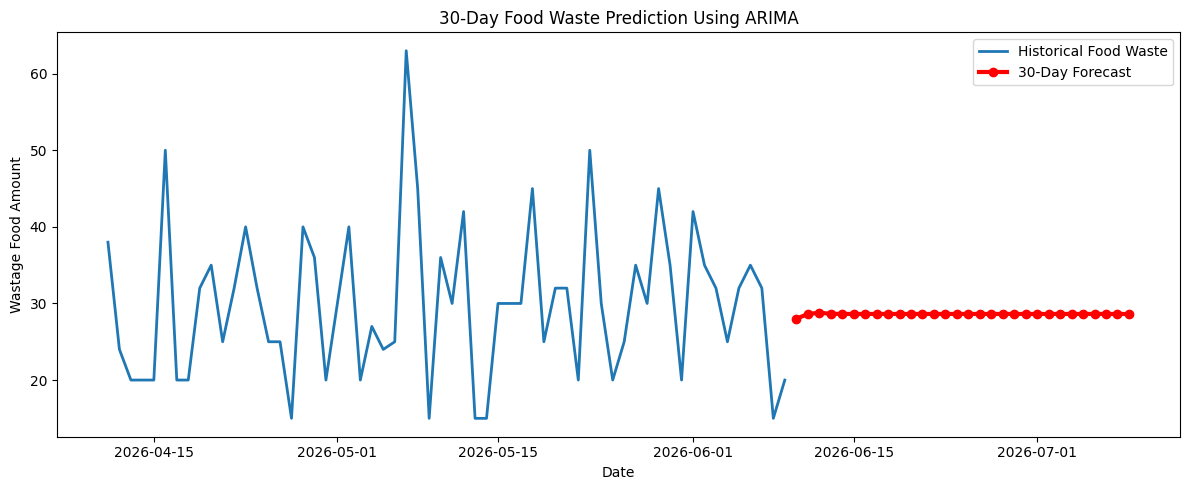

In [ ]:
forecast = model_fit.forecast(steps=30)

print(forecast)

plt.figure(figsize=(12,5))

# recent actual data
plt.plot(
    ts[-60:],
    label='Historical Food Waste',
    linewidth=2
)

# future prediction
plt.plot(
    forecast.index,
    forecast,
    label='30-Day Forecast',
    color='red',
    linewidth=3,
    marker='o'
)

plt.title('30-Day Food Waste Prediction Using ARIMA')

plt.xlabel('Date')

plt.ylabel('Wastage Food Amount')

plt.legend()

plt.tight_layout()

plt.show()

12. MODEL EVALUATION

In [ ]:
train = ts[:-7]
test = ts[-7:]

model = ARIMA(train, order=((3,1,1)))

model_fit = model.fit()

forecast = model_fit.forecast(steps=7)

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(
    mean_squared_error(test, forecast)
)

print("MAE:", mae)

print("RMSE:", rmse)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


MAE: 5.96209323191358
RMSE: 7.016166509361195


13. MONTHLY FOOD WASTE ANALYSIS

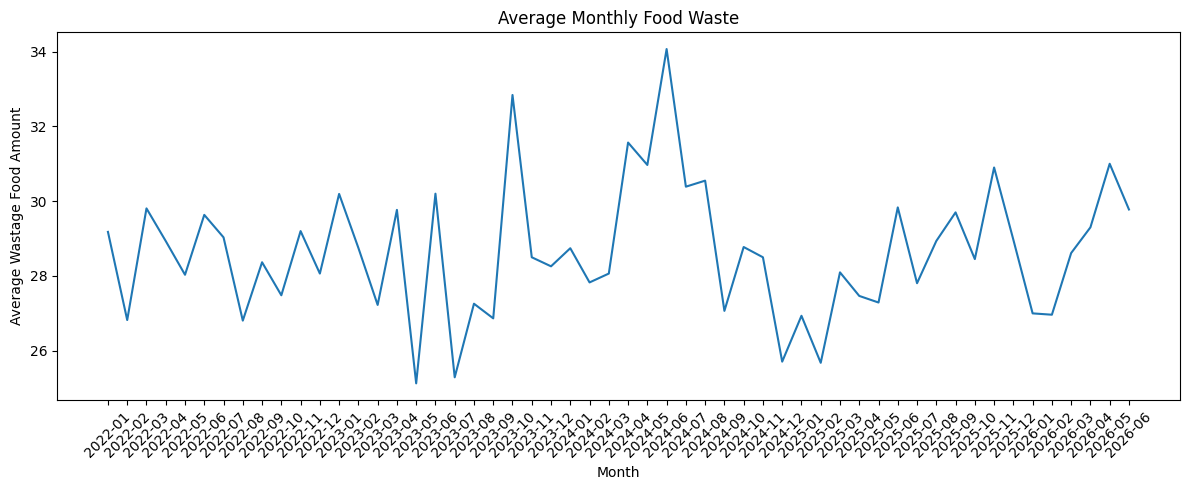

In [ ]:
monthly_waste = restaurant_df.groupby(
    restaurant_df['Date'].dt.to_period('M')
)['Wastage Food Amount'].mean()

monthly_waste.index = monthly_waste.index.astype(str)

plt.figure(figsize=(12,5))

plt.plot(monthly_waste)

plt.title('Average Monthly Food Waste')

plt.xlabel('Month')

plt.ylabel('Average Wastage Food Amount')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

14. DONATION RECOMMENDATION

In [ ]:
# Create future dates (7 days after 11/06/2026)
future_dates = pd.date_range(
    start='2026-06-12',
    periods=7,
    freq='D'
)

# Generate 7-day forecast
forecast = model_fit.forecast(
    steps=7
)

# Replace forecast dates
forecast.index = future_dates

recommendation = []

for value in forecast:

    if value >= 35:
        recommendation.append(
            'Immediate Donation'
        )

    elif value >= 25:
        recommendation.append(
            'Planned Donation'
        )

    else:
        recommendation.append(
            'Normal Management'
        )

# Create recommendation table
donation_df = pd.DataFrame({

    'Date': forecast.index.date,  # remove time

    'Forecasted Waste':
    forecast.values.round(2),

    'Recommendation':
    recommendation
})

# Center align table
donation_df.style.set_properties(
    **{
        'text-align': 'center'
    }
).set_table_styles(
    [{
        'selector': 'th',
        'props': [('text-align', 'center')]
    }]
)

,Date,Forecasted Waste,Recommendation
0,2026-06-12,29.360000,Planned Donation
1,2026-06-13,28.590000,Planned Donation
2,2026-06-14,28.520000,Planned Donation
3,2026-06-15,28.620000,Planned Donation
4,2026-06-16,28.630000,Planned Donation
5,2026-06-17,28.640000,Planned Donation
6,2026-06-18,28.640000,Planned Donation


## 15. Hypothesis Testing: Null and Alternative Hypotheses

In statistics, a **hypothesis test** is a method for making a decision about a population parameter based on sample data. The core of hypothesis testing involves two competing statements:

### Null Hypothesis (H0)
The null hypothesis is a statement that there is no effect or no difference. It often represents the status quo or a statement of no change. We usually assume the null hypothesis is true until proven otherwise. For example:
*   The average food waste is 30 units.
*   There is no difference in food waste between two different event types.

### Alternative Hypothesis (H1 or Ha)
The alternative hypothesis is a statement that contradicts the null hypothesis. It's what you are trying to prove or what you suspect might be true. For example:
*   The average food waste is *not* 30 units.
*   The average food waste is *greater than* 30 units.
*   There *is* a difference in food waste between two different event types.

### Steps for Hypothesis Testing:
1.  **State the Null and Alternative Hypotheses:** Clearly define H0 and H1.
2.  **Choose a Significance Level (α):** This is the probability of rejecting the null hypothesis when it is actually true (Type I error). Common values are 0.05 or 0.01.
3.  **Collect Data and Calculate Test Statistic:** Use your sample data to compute a test statistic (e.g., t-statistic, z-statistic, F-statistic).
4.  **Determine the p-value:** The p-value is the probability of observing a test statistic as extreme as, or more extreme than, the one calculated from your sample data, *assuming the null hypothesis is true*.
5.  **Make a Decision:**
    *   If p-value ≤ α, reject the null hypothesis.
    *   If p-value > α, fail to reject the null hypothesis.

Let's demonstrate with an example using a t-test.

## Example: One-Sample T-Test for Food Waste

Let's assume we want to test if the average `Wastage Food Amount` is significantly different from a hypothetical value, say 30 units. This could be a regulatory target or a historical average.

**Hypotheses:**
*   **Null Hypothesis (H0):** The average food wastage is equal to 30 units (μ = 30).
*   **Alternative Hypothesis (H1):** The average food wastage is not equal to 30 units (μ ≠ 30).

In [ ]:
# Import necessary library for t-test
from scipy import stats

# Define the sample data (Wastage Food Amount from our restaurant_df)
sample_data = restaurant_df['Wastage Food Amount']

# Define the hypothetical population mean (mu_0)
hypothesized_mean = 30

# Perform the one-sample t-test
# `equal_var=False` is often used when population variances are unknown and assumed to be unequal.
# For a single sample t-test, it's not directly applicable in the same way as a two-sample test,
# but for clarity, we are testing against a specific mean.
t_statistic, p_value = stats.ttest_1samp(sample_data, popmean=hypothesized_mean)

# Define the significance level
alpha = 0.05

print(f"Sample Mean: {sample_data.mean():.2f}")
print(f"Hypothesized Mean (H0): {hypothesized_mean}")
print(f"T-statistic: {t_statistic:.3f}")
print(f"P-value: {p_value:.3f}")
print(f"Significance Level (alpha): {alpha}")

# Make a decision
if p_value <= alpha:
    print("\nDecision: Reject the null hypothesis (H0).")
    print("Conclusion: The average food wastage is significantly different from 30 units.")
elif p_value > alpha:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is not enough evidence to say that the average food wastage is significantly different from 30 units.")

Sample Mean: 28.63
Hypothesized Mean (H0): 30
T-statistic: -5.305
P-value: 0.000
Significance Level (alpha): 0.05

Decision: Reject the null hypothesis (H0).
Conclusion: The average food wastage is significantly different from 30 units.
